<a href="https://colab.research.google.com/github/VictorPortolani/am-turma5/blob/main/RedesNeurais_Aula1027.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Conector Drive e Pre-Load de Dados [Credit]

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import pickle
with open('/content/drive/MyDrive/am-t5/credit.pkl', 'rb') as f:
  X_credit_train, y_credit_train, X_credit_test, y_credit_test = pickle.load(f)

Provedor de Treino [25%]

In [6]:
X_credit_test.shape, y_credit_test.shape

((500, 3), (500,))

Provedor de Testes [75%]

In [7]:
X_credit_train.shape, y_credit_train.shape

((1500, 3), (1500,))

# Redes Neurais [Cradit Data]

In [14]:
parametros = {'activation':['relu','logistic', 'tanh'],
              'solver':['adam', 'sgd'],
              'batch_size':[10,56]}

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.neural_network import MLPClassifier

In [15]:
grid_search = GridSearchCV(estimator = MLPClassifier(),param_grid=parametros)
grid_search.fit(X_credit_train, y_credit_train)
melhores_parametros = grid_search.best_params_
melhor_resultado = grid_search.best_score_
print(melhores_parametros)
print(melhor_resultado)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptro

{'activation': 'relu', 'batch_size': 10, 'solver': 'adam'}
0.9959999999999999


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import DecisionBoundaryDisplay

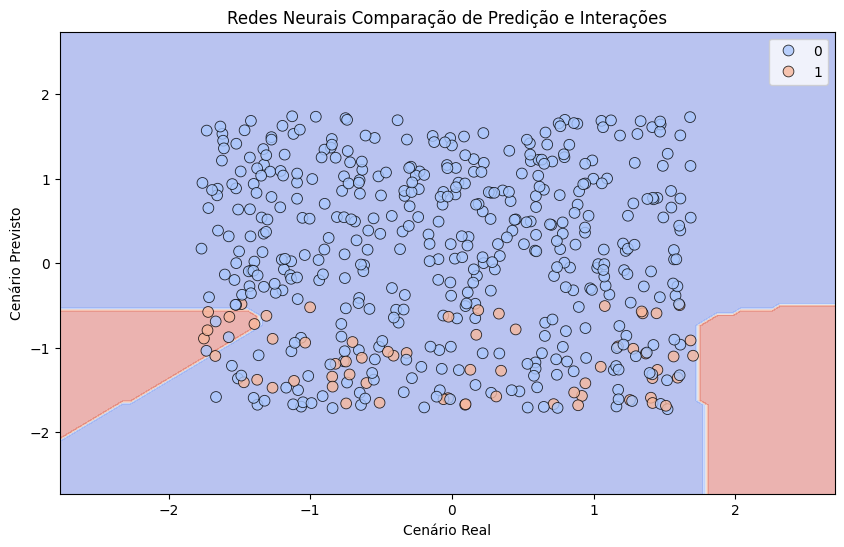

In [19]:
x_2d = X_credit_test[:, :2]
rna_2d = MLPClassifier(**grid_search.best_params_, max_iter=1000, random_state=42)
rna_2d.fit(x_2d, y_credit_test)

fig, ax = plt.subplots(figsize=(10, 6))
DecisionBoundaryDisplay.from_estimator(
    rna_2d,
    x_2d,
    cmap="coolwarm",
    alpha=0.4,
    ax=ax,
    response_method="predict"
)
sns.scatterplot(
    x=x_2d[:, 0],
    y=x_2d[:, 1],
    hue=y_credit_test,
    palette="coolwarm",
    edgecolor="black",
    alpha=0.8,
    s=60,
    ax=ax
)
plt.title("Redes Neurais Comparação de Predição e Interações")
plt.xlabel("Cenário Real")
plt.ylabel("Cenário Previsto")
plt.show()